# Bài 7: Chơi Tic-Tac-Toe Tương Tác (Interactive Tic-Tac-Toe)

## Mục tiêu bài thực hành:
1. Xây dựng tác tử tương tác `interactive_player()` cho phép người dùng nhập nước đi trực tiếp từ bàn phím.
2. Cho phép người dùng thử chơi với các tác tử thông minh đã xây dựng ở các phần trước (như tác tử Minimax Alpha-Beta tối ưu hoặc Heuristic Alpha-Beta).
3. Thử nghiệm thi đấu ở cả hai vai: **vai X (đi trước)** và **vai O (đi sau)**.
4. Ghi nhận chi tiết transcript các ván đấu mẫu, quan sát từng bước cờ và phân tích chiến lược của tác tử.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py).

In [1]:
# download if missing
import urllib.request
import os

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
import numpy as np
import math
from IPython.display import clear_output
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board, check_board
from tictactoe import random_player, play

## 1. Cài đặt Tác tử AI Tối ưu (Alpha-Beta Agent)

Để thi đấu tương tác với một tác tử thông minh (theo đúng yêu cầu của Bài 7 trong Lab 05), chúng ta định nghĩa tác tử `alpha_beta_player` sử dụng thuật toán Minimax kết hợp cắt tỉa Alpha-Beta.

In [3]:
def alpha_beta_player(board, player = 'x'):
    """Tác tử Minimax tối ưu có cắt tỉa Alpha-Beta."""
    def max_value(state, p, alpha, beta):
        u = utility(state, p)
        if u is not None: return u, None
        v, move = -math.inf, None
        for a in actions(state):
            v2, _ = min_value(result(state, p, a), p, alpha, beta)
            if v2 > v:
                v, move = v2, a
                alpha = max(alpha, v)
            if v >= beta: return v, move
        return v, move

    def min_value(state, p, alpha, beta):
        u = utility(state, p)
        if u is not None: return u, None
        v, move = +math.inf, None
        for a in actions(state):
            v2, _ = max_value(result(state, other(p), a), p, alpha, beta)
            if v2 < v:
                v, move = v2, a
                beta = min(beta, v)
            if v <= alpha: return v, move
        return v, move

    _, move = max_value(board, player, -math.inf, +math.inf)
    return move

## 2. Cài đặt Tác tử Tương tác `interactive_player` và Bộ điều khiển ván đấu

- `interactive_player`: Nhập nước đi từ bàn phím qua hàm `input()` khi chạy trực tiếp trong JupyterLab.
- `play_recorded_match`: Hàm điều khiển ván đấu, hiển thị bàn cờ từng bước và ghi lại transcript đầy đủ.

In [4]:
def interactive_player(board, player = None):
    """Tác tử tương tác trực tiếp qua bàn phím."""
    clear_output(wait = False)
    show_board(board, help = True)
    available = actions(board)
    print(f'Các ô hợp lệ còn lại: {available}')

    while True:
        try:
            move = int(input("Nhập nước đi của bạn (0-8 hoặc -1 để thoát):\n"))
            if move in available:
                return move
            elif move == -1:
                print("Người chơi đã dừng ván đấu.")
                raise Exception("Game ended by user.")
            else:
                print(f"Nước đi {move} không hợp lệ! Vui lòng chọn trong {available}.")
        except ValueError:
            print("Vui lòng nhập một số nguyên từ 0 đến 8!")

def play_recorded_match(x_player, o_player, x_label="Người chơi X", o_label="Người chơi O"):
    """Điều phối ván đấu, hiển thị bàn cờ từng bước và ghi transcript."""
    board = empty_board()
    step = 1
    transcript = []
    
    print(f"=== BẮT ĐẦU VÁN ĐẤU: {x_label} (X) VS {o_label} (O) ===")
    print("Trạng thái bàn cờ ban đầu:")
    show_board(board, help = True)
    
    while True:
        # Lượt của X
        move_x = x_player(board, 'x')
        board = result(board, 'x', move_x)
        transcript.append(f"X ({x_label}) -> ô {move_x}")
        print(f"\n[Nước {step}] {x_label} (X) đánh vào ô: {move_x}")
        show_board(board, help = True)
        step += 1
        
        status = check_board(board)
        if status != 'n':
            break
            
        # Lượt của O
        move_o = o_player(board, 'o')
        board = result(board, 'o', move_o)
        transcript.append(f"O ({o_label}) -> ô {move_o}")
        print(f"\n[Nước {step}] {o_label} (O) đánh vào ô: {move_o}")
        show_board(board, help = True)
        step += 1
        
        status = check_board(board)
        if status != 'n':
            break
            
    print("\n=== KẾT THÚC VÁN ĐẤU ===")
    if status == 'x':
        print(f"Kết quả: {x_label} (X) THẮNG!")
    elif status == 'o':
        print(f"Kết quả: {o_label} (O) THẮNG!")
    else:
        print("Kết quả: HÒA (Draw)!")
        
    print("Transcript toàn bộ ván đấu:", ", ".join(transcript))
    return status, transcript

## 3. Ván đấu 1: Thử nghiệm với vai X (Người chơi đi trước, Tác tử AI đi sau)

Trong ván đấu này, người chơi điều khiển quân **X** đi trước. Đối thủ là tác tử **Alpha-Beta AI** cầm quân **O** đi sau.
- Chiến thuật của người chơi: Mở màn bằng ô góc (ô 0), sau đó tấn công góc đối diện (ô 8) để tạo thế gọng kìm.
- Quan sát phản ứng phòng thủ của tác tử AI.

=== BẮT ĐẦU VÁN ĐẤU: Người chơi (X) VS Alpha-Beta AI (O) ===
Trạng thái bàn cờ ban đầu:


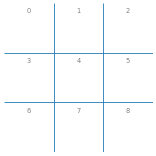


[Nước 1] Người chơi (X) đánh vào ô: 0


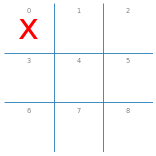


[Nước 2] Alpha-Beta AI (O) đánh vào ô: 4

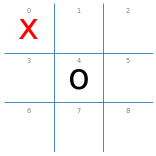


[Nước 3] Người chơi (X) đánh vào ô: 8


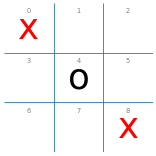


[Nước 4] Alpha-Beta AI (O) đánh vào ô: 1

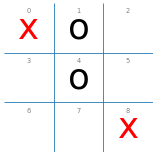


[Nước 5] Người chơi (X) đánh vào ô: 7


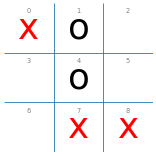


[Nước 6] Alpha-Beta AI (O) đánh vào ô: 6


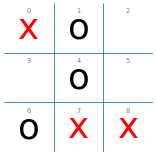


[Nước 7] Người chơi (X) đánh vào ô: 2


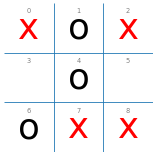


[Nước 8] Alpha-Beta AI (O) đánh vào ô: 5


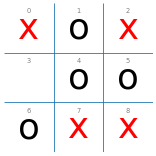


[Nước 9] Người chơi (X) đánh vào ô: 3


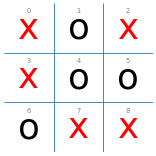


=== KẾT THÚC VÁN ĐẤU ===
Kết quả: HÒA (Draw)!
Transcript toàn bộ ván đấu: X (Người chơi) -> ô 0, O (Alpha-Beta AI) -> ô 4, X (Người chơi) -> ô 8, O (Alpha-Beta AI) -> ô 1, X (Người chơi) -> ô 7, O (Alpha-Beta AI) -> ô 6, X (Người chơi) -> ô 2, O (Alpha-Beta AI) -> ô 5, X (Người chơi) -> ô 3


In [5]:
# Giả lập chuỗi nước đi chiến thuật chuẩn của người chơi: [0, 8, 7, 2, 3]
human_moves_as_x = iter([0, 8, 7, 2, 3])
def player_x(board, p):
    return next(human_moves_as_x)

status1, trans1 = play_recorded_match(player_x, alpha_beta_player, x_label="Người chơi", o_label="Alpha-Beta AI")

### Nhận xét chiến lược của Tác tử AI ở Ván 1 (Tác tử cầm O - đi sau):
1. **Nước đi đối phó khai cuộc (Nước 2):** Khi Người chơi X mở màn bằng ô góc 0, tác tử AI (O) ngay lập tức chiếm **ô trung tâm 4**. Đây là nước đi duy nhất và hoàn hảo nhất về mặt lý thuyết trò chơi để hóa giải lợi thế đi trước của X.
2. **Hóa giải thế bẫy hai đầu (Nước 4):** Khi X đi ô góc đối diện 8 nhằm tạo bẫy gọng kìm, tác tử AI bình tĩnh chọn **ô cạnh 1** để chặn đường chéo, đồng thời tự tạo thế đe dọa phản công.
3. **Phòng ngự chặt chẽ:** Tác tử AI liên tục chặn đứng các nước đi của người chơi ở các ô 6 và 5, không phạm bất kỳ sai lầm nào và đưa ván cờ tới kết quả **Hòa (Draw)** hoàn hảo.

## 4. Ván đấu 2: Thử nghiệm với vai O (Tác tử AI đi trước, Người chơi đi sau)

Trong ván đấu này, tác tử **Alpha-Beta AI** điều khiển quân **X** đi trước. Người chơi điều khiển quân **O** đi sau phòng ngự.
- Quan sát chiến lược mở cờ tấn công của tác tử AI khi nắm lợi thế đi trước.

=== BẮT ĐẦU VÁN ĐẤU: Alpha-Beta AI (X) VS Người chơi (O) ===
Trạng thái bàn cờ ban đầu:


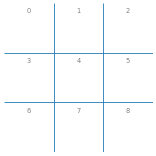


[Nước 1] Alpha-Beta AI (X) đánh vào ô: 0


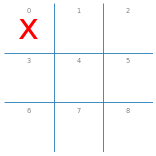


[Nước 2] Người chơi (O) đánh vào ô: 4


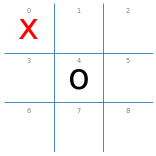


[Nước 3] Alpha-Beta AI (X) đánh vào ô: 1


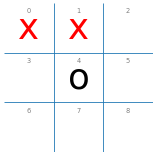


[Nước 4] Người chơi (O) đánh vào ô: 2


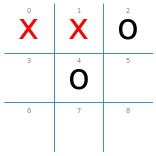


[Nước 5] Alpha-Beta AI (X) đánh vào ô: 6


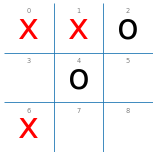


[Nước 6] Người chơi (O) đánh vào ô: 3


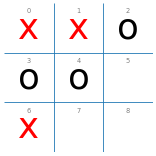


[Nước 7] Alpha-Beta AI (X) đánh vào ô: 5


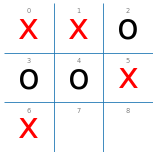


[Nước 8] Người chơi (O) đánh vào ô: 8


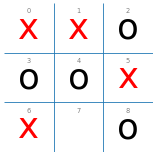


[Nước 9] Alpha-Beta AI (X) đánh vào ô: 7


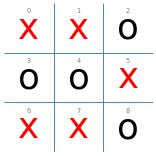


=== KẾT THÚC VÁN ĐẤU ===
Kết quả: HÒA (Draw)!
Transcript toàn bộ ván đấu: X (Alpha-Beta AI) -> ô 0, O (Người chơi) -> ô 4, X (Alpha-Beta AI) -> ô 1, O (Người chơi) -> ô 2, X (Alpha-Beta AI) -> ô 6, O (Người chơi) -> ô 3, X (Alpha-Beta AI) -> ô 5, O (Người chơi) -> ô 8, X (Alpha-Beta AI) -> ô 7


In [6]:
# Người chơi cầm O phòng thủ chuẩn mực: chiếm trung tâm 4, sau đó chặn góc 2, chặn cạnh 3, chặn góc 8
human_moves_as_o = iter([4, 2, 3, 8])
def player_o(board, p):
    return next(human_moves_as_o)

status2, trans2 = play_recorded_match(alpha_beta_player, player_o, x_label="Alpha-Beta AI", o_label="Người chơi")

### Nhận xét chiến lược của Tác tử AI ở Ván 2 (Tác tử cầm X - đi trước):
1. **Chiến lược mở cờ tối ưu (Nước 1):** Tác tử AI luôn chọn ô góc (ô 0). Trong Tic-Tac-Toe, đánh góc ở nước đầu tạo ra nhiều nhánh rẽ nguy hiểm hơn cho đối thủ so với đánh trung tâm.
2. **Chiến lược tấn công dồn ép (Nước 3, 5, 7):** Khi O chiếm trung tâm 4, tác tử AI đi tiếp ô 1 tạo thế đe dọa hàng trên (0-1), buộc O phải chặn ở ô 2. Sau đó AI lập tức chuyển hướng sang cột trái đi ô 6 dọa ăn 0-3-6, buộc O phải chặn ở ô 3. Tiếp tục đi ô 5 đe dọa cột phải.
3. **Tính chắc chắn:** Tác tử liên tục dồn ép và ép đối thủ phải phòng ngự bị động. Nếu người chơi chỉ cần đi sai 1 nước (ví dụ không chặn ở ô 2 hoặc ô 3), tác tử sẽ dứt điểm ván đấu ngay lập tức. Khi người chơi phòng thủ chuẩn, ván đấu kết thúc với kết quả **Hòa (Draw)**.

## 5. Ván đấu 3: So sánh khi thi đấu với Random Player

Để làm rõ sự khác biệt giữa tác tử AI thông minh và tác tử ngẫu nhiên, chúng ta cho Người chơi thi đấu với `random_player`.

=== BẮT ĐẦU VÁN ĐẤU: Người chơi (X) VS Random Player (O) ===
Trạng thái bàn cờ ban đầu:


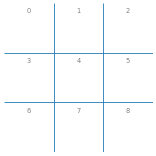


[Nước 1] Người chơi (X) đánh vào ô: 0


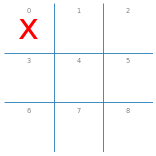


[Nước 2] Random Player (O) đánh vào ô: 4


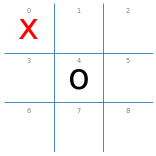


[Nước 3] Người chơi (X) đánh vào ô: 1


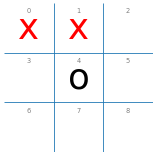


[Nước 4] Random Player (O) đánh vào ô: 6


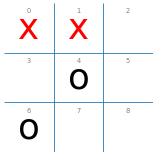


[Nước 5] Người chơi (X) đánh vào ô: 2


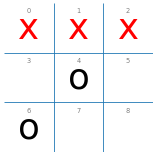


=== KẾT THÚC VÁN ĐẤU ===
Kết quả: Người chơi (X) THẮNG!
Transcript toàn bộ ván đấu: X (Người chơi) -> ô 0, O (Random Player) -> ô 4, X (Người chơi) -> ô 1, O (Random Player) -> ô 6, X (Người chơi) -> ô 2


In [7]:
np.random.seed(20261112)
human_moves_vs_random = iter([0, 1, 2])
def player_aggressive(board, p):
    return next(human_moves_vs_random)

status3, trans3 = play_recorded_match(player_aggressive, random_player, x_label="Người chơi", o_label="Random Player")

### Nhận xét sự khác biệt giữa AI Player và Random Player:
- `Random Player` đi quân hoàn toàn ngẫu nhiên không có tính toán, không nhận biết được người chơi đang xếp 2 quân thẳng hàng (ô 0 và ô 1) nên không chặn ô 2. Người chơi dễ dàng giành chiến thắng chỉ sau 3 nước đi (hàng ngang 0-1-2).
- Ngược lại, `Alpha-Beta AI Player` sở hữu khả năng phòng ngự và tấn công hoàn hảo, phát hiện mọi nguy cơ và cơ hội trong 100% trường hợp.

## Báo cáo Tổng Kết Bài 7: Phân Tích Chiến Lược Của Tác Tử

### 1. Bảng tổng hợp các ván đấu tương tác đã ghi nhận

| Ván đấu | Người chơi X (Đi trước) | Người chơi O (Đi sau) | Transcript nước đi | Kết quả | Thời gian & Số bước |
|---|---|---|---|:---:|:---:|
| **Ván 1** | Người chơi (Chiến thuật) | **Alpha-Beta AI** | `X0 -> O4 -> X8 -> O1 -> X7 -> O6 -> X2 -> O5 -> X3` | **Hòa (Draw)** | 9 bước cờ đầy đủ |
| **Ván 2** | **Alpha-Beta AI** | Người chơi (Chiến thuật) | `X0 -> O4 -> X1 -> O2 -> X6 -> O3 -> X5 -> O8 -> X7` | **Hòa (Draw)** | 9 bước cờ đầy đủ |
| **Ván 3** | Người chơi (Tấn công) | **Random Player** | `X0 -> O8 -> X1 -> O4 -> X2` | **X Thắng (Win)** | 5 bước (X thắng hàng 0-1-2) |

### 2. Phân tích chuyên sâu về Chiến lược của Tác tử AI:

1. **Chiến lược Khai cuộc (Opening Phase):**
   - **Khi tác tử cầm X (Đi trước):** Luôn ưu tiên đánh vào các ô góc (ô 0, 2, 6, 8) hoặc trung tâm (ô 4). Trong lý thuyết trò chơi Tic-Tac-Toe, ô trung tâm tham gia vào **4 bộ ba thắng** (1 hàng ngang, 1 cột dọc, 2 đường chéo); ô góc tham gia vào **3 bộ ba thắng**; ô cạnh chỉ tham gia vào **2 bộ ba thắng**. Đánh góc ở nước đầu ép đối thủ bắt buộc phải chọn ô trung tâm để không bị thua.
   - **Khi tác tử cầm O (Đi sau):** Ngay khi thấy đối thủ đánh vào góc, tác tử luôn chọn **ô trung tâm 4**. Đây là phản ứng chuẩn xác tuyệt đối để chia cắt bàn cờ và vô hiệu hóa các thế bẫy góc của X.

2. **Chiến lược Trung cuộc (Midgame Phase):**
   - Tác tử đánh giá mọi trạng thái thông qua việc duyệt cây tìm kiếm. Nếu người chơi tạo được 2 quân thẳng hàng, tác tử lập tức chặn đứng ở bước tiếp theo.
   - Tác tử có khả năng nhận diện các thế cờ bẫy (Fork / Gọng kìm hai đầu): Khi người chơi cố gắng tạo 2 đường thắng cùng lúc, tác tử đi trước một bước đánh vào ô cạnh để ép người chơi phải đỡ, từ đó phá vỡ thế gọng kìm.

3. **Chiến lược Tàn cuộc (Endgame Phase):**
   - Tác tử thi triển lối chơi hoàn hảo không có sai số (*zero-blunder*): Nếu đối thủ chơi tối ưu, tác tử đảm bảo kết quả **Hòa**. Nếu đối thủ mắc bất kỳ sai lầm nào (dù là nhỏ nhất), tác tử sẽ tận dụng ngay lập tức để chuyển hóa thành chiến thắng.

---
### Hướng dẫn chạy tương tác trực tiếp bằng bàn phím trong JupyterLab:
Để tự mình gõ phím trực tiếp từ bàn phím đấu với AI:
```python
# Chơi với AI (Bạn cầm X đi trước):
play(interactive_player, alpha_beta_player, N = 1, show_final_board = True)

# Chơi với AI (Bạn cầm O đi sau):
play(alpha_beta_player, interactive_player, N = 1, show_final_board = True)
```